# Bayesian learner: linear-Gaussian Naive Bayes

## Preprocessing

In [1]:
import numpy as np
import polars as pl
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
FEATURES = [
    "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight",
    "is_infant", "is_female",
]

# cleaning and sex encoding (fixed rules, before the split)
df = pl.read_csv("./data/abalone.csv.zst")
df = df.filter(~((pl.col("height") == 0) | (pl.col("height") > 0.3)))
df = df.with_columns(
    is_infant=(pl.col("sex") == "I").cast(pl.Int8),
    is_female=(pl.col("sex") == "F").cast(pl.Int8),
).drop("sex")

# 20% hold-out test (not used until the end) and 5 stratified folds on the development part
rings_all = df["rings"].to_numpy()
y_bins = np.digitize(rings_all, np.quantile(rings_all, [0.2, 0.4, 0.6, 0.8]))
dev_idx, test_idx = train_test_split(np.arange(df.height), test_size=0.2, random_state=SEED, stratify=y_bins)
dev, test = df[dev_idx], df[test_idx]
X, rings = dev.select(FEATURES).to_numpy(), dev["rings"].to_numpy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y_bins[dev_idx]))


def cross_validate(fit_predict, verbose=True):
    """fit_predict(X_train, y_train, X_val) -> predictions. Standardization is fitted on each training part."""
    scores = []
    for tr, va in folds:
        scaler = StandardScaler().fit(X[tr])
        pred = fit_predict(scaler.transform(X[tr]), rings[tr], scaler.transform(X[va]))
        scores.append((root_mean_squared_error(rings[va], pred), mean_absolute_error(rings[va], pred), r2_score(rings[va], pred)))
    scores = np.array(scores)
    m, sd = scores.mean(axis=0), scores.std(axis=0, ddof=1)
    if verbose:
        print(f"RMSE {m[0]:.3f} ± {sd[0]:.3f}   MAE {m[1]:.3f} ± {sd[1]:.3f}   R² {m[2]:.3f} ± {sd[2]:.3f}")
    return scores


baseline = cross_validate(lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))

RMSE 3.226 ± 0.159   MAE 2.366 ± 0.084   R² -0.001 ± 0.001


## Model: Naive Bayes for regression

Bayes' rule asks: given the measurements `x` of an animal, how many rings `y` is it likely to have?


* **Prior, what we believe before measuring:** `rings` follows a bell curve with the mean and variance of the training `rings`.
* **Each feature given the rings:** every feature is a straight line of `rings` plus noise, `x_j ≈ a_j + b_j · y`. It is fitted by least squares of the feature **on** `rings`, the opposite direction to ordinary regression, so it gives a slope `b_j`, an intercept `a_j` and the noise `s_j²`.
* **Naive assumption:** given the rings, the features are independent, so their factors are simply multiplied.

In [2]:
def fit_lgnb(X_tr, y_tr):
    mu, tau2 = y_tr.mean(), y_tr.var()
    A = np.c_[y_tr, np.ones(len(y_tr))]
    coef = np.linalg.lstsq(A, X_tr, rcond=None)[0]       # x_j = b_j y + a_j, all features at once
    b, a = coef[0], coef[1]
    s2 = ((X_tr - A @ coef) ** 2).mean(axis=0)
    return mu, tau2, a, b, s2


def predict_lgnb(model, X):
    mu, tau2, a, b, s2 = model
    precision = 1 / tau2 + np.sum(b**2 / s2)
    mean = (mu / tau2 + ((X - a) * b / s2).sum(axis=1)) / precision
    return mean, np.sqrt(1 / precision)                  # posterior mean and sd (the sd is the same for every row)


bayes = cross_validate(lambda X_tr, y_tr, X_va: predict_lgnb(fit_lgnb(X_tr, y_tr), X_va)[0])

# what the model learned, on the whole development part (only to read it, not to score it)
X_dev = StandardScaler().fit_transform(X)
model = fit_lgnb(X_dev, rings)
print(pl.DataFrame({
    "feature": FEATURES, "a_j": model[2].round(3), "b_j": model[3].round(3), "s_j^2": model[4].round(3),
    "precision b^2/s^2": (model[3] ** 2 / model[4]).round(3),
}))
print(f"prior precision 1/tau^2 = {1 / model[1]:.3f}, posterior sd of rings = {predict_lgnb(model, X_dev[:1])[1]:.3f}")

RMSE 3.480 ± 0.071   MAE 2.803 ± 0.046   R² -0.170 ± 0.101
shape: (9, 5)
┌────────────────┬────────┬────────┬───────┬───────────────────┐
│ feature        ┆ a_j    ┆ b_j    ┆ s_j^2 ┆ precision b^2/s^2 │
│ ---            ┆ ---    ┆ ---    ┆ ---   ┆ ---               │
│ str            ┆ f64    ┆ f64    ┆ f64   ┆ f64               │
╞════════════════╪════════╪════════╪═══════╪═══════════════════╡
│ length         ┆ -1.715 ┆ 0.172  ┆ 0.69  ┆ 0.043             │
│ diameter       ┆ -1.77  ┆ 0.178  ┆ 0.67  ┆ 0.047             │
│ height         ┆ -1.882 ┆ 0.189  ┆ 0.627 ┆ 0.057             │
│ whole_weight   ┆ -1.653 ┆ 0.166  ┆ 0.712 ┆ 0.039             │
│ shucked_weight ┆ -1.282 ┆ 0.129  ┆ 0.827 ┆ 0.02              │
│ viscera_weight ┆ -1.543 ┆ 0.155  ┆ 0.749 ┆ 0.032             │
│ shell_weight   ┆ -1.927 ┆ 0.194  ┆ 0.608 ┆ 0.062             │
│ is_infant      ┆ 1.368  ┆ -0.138 ┆ 0.802 ┆ 0.024             │
│ is_female      ┆ -0.785 ┆ 0.079  ┆ 0.935 ┆ 0.007             │
└────────────────

In [3]:
from sklearn.decomposition import PCA


def naive_bayes_pca(X_tr, y_tr, X_va):
    pca = PCA().fit(X_tr)
    return predict_lgnb(fit_lgnb(pca.transform(X_tr), y_tr), pca.transform(X_va))[0]


bayes_pca = cross_validate(naive_bayes_pca)

RMSE 2.264 ± 0.095   MAE 1.633 ± 0.029   R² 0.507 ± 0.019


### Why Naive Bayes does badly here

Naive Bayes assumes the features are **independent given the target**. For the seven size and weight features this assumption is badly violated: they are almost copies of each other (median |correlation| 0.89, 14 of the 36 pairs above 0.9), because they all measure how big the animal is.

The model does not know this. It treats each of the seven as a separate witness and adds up their evidence, so the same information about the size is counted several times. The prediction is pushed too far, and the model is over-confident: its posterior sd is about 1.5 rings while the real error is about 3.5. The result (RMSE 3.480, R² −0.17) is worse than the mean baseline (3.226).

The PCA comparison supports this explanation. PCA rotates the same 9 features into uncorrelated ones, with no information added or removed, and Naive Bayes on them gets RMSE 2.264, close to OLS (2.183). So the cause is the dependence between the features, not the Gaussian or linear form of the model.

The assumption holds better between the size features and the two `sex` columns (the smallest correlation is 0.26). Uncorrelated is not the same as independent, but here it is close enough to repair most of the error.

## Final evaluation on the test set

The model has no hyper-parameters. It is refitted on the **whole development part** (3338 rows) and scored **once** on the 20% test set (835 rows).

baseline   test RMSE 3.207   MAE 2.351   R² -0.000
Naive Bayes test RMSE 3.501   MAE 2.858   R² -0.192


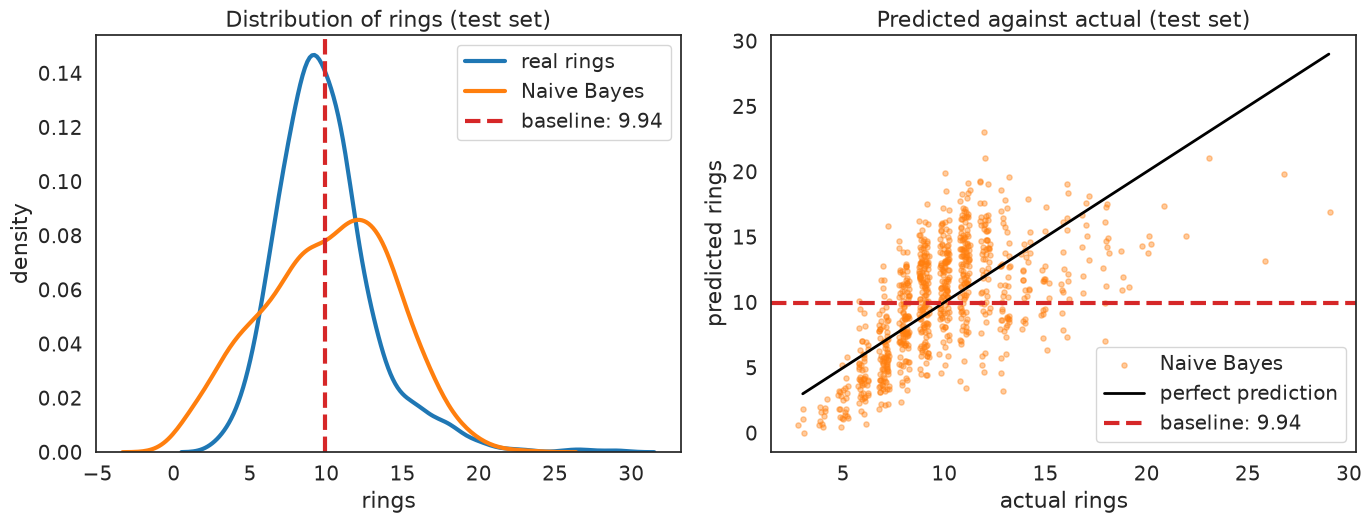

In [4]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

def test_evaluate(name, fit_predict):
    """Refit on the whole development part (standardized with its own mean and sd) and score once on the test set."""
    scaler = StandardScaler().fit(X)
    y = test["rings"].to_numpy()
    pred = fit_predict(scaler.transform(X), rings, scaler.transform(test.select(FEATURES).to_numpy()))
    print(f"{name:10s} test RMSE {root_mean_squared_error(y, pred):.3f}   MAE {mean_absolute_error(y, pred):.3f}   R² {r2_score(y, pred):.3f}")
    return pred


def plot_test(pred, name):
    """Left: distribution of the real rings, of the predictions and of the baseline. Right: predicted against actual."""
    y_test, base = test["rings"].to_numpy(), rings.mean()
    jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(y_test))  # rings are integers: spread the dots sideways
    with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.3):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
        sns.kdeplot(y_test, ax=ax1, lw=3, color="C0", label="real rings")
        sns.kdeplot(pred, ax=ax1, lw=3, color="C1", label=name)
        ax1.axvline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax1.set(title="Distribution of rings (test set)", xlabel="rings", ylabel="density")
        ax1.legend()
        ax2.scatter(y_test + jitter, pred, s=14, alpha=0.4, color="C1", label=name)
        ax2.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="k", lw=2, label="perfect prediction")
        ax2.axhline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax2.set(title="Predicted against actual (test set)", xlabel="actual rings", ylabel="predicted rings")
        ax2.legend()
        plt.tight_layout()
        plt.show()


test_evaluate("baseline", lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))
final = lambda X_tr, y_tr, X_va: predict_lgnb(fit_lgnb(X_tr, y_tr), X_va)[0]
pred = test_evaluate("Naive Bayes", final)
plot_test(pred, "Naive Bayes")

# validation scores of the chosen model and its test predictions, for the comparison in evaluation.ipynb
val = cross_validate(final, verbose=False)
Path("results").mkdir(exist_ok=True)
np.savez("results/bayesians.npz", val_rmse=val[:, 0], baseline_rmse=baseline[:, 0], test_y=test["rings"].to_numpy(), test_pred=pred)